# Experiment 5: DBSCAN Clustering

**Objective:**
1. Generate synthetic 2D cluster data with added uniform random noise.
2. Standardize features using `StandardScaler`.
3. Apply DBSCAN (Density-Based Spatial Clustering of Applications with Noise).
4. Identify cluster count and noise points (labeled as `-1`).
5. Evaluate cluster quality using Silhouette Score and visualize the clusters.

### Step 1: Import Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

### Step 2: Generate Synthetic Data with Noise

In [2]:
# Generate 3 cluster blobs (total 600 points)
X_blobs, y_blobs = make_blobs(
    n_samples=[200, 200, 200],
    centers=[(-5, -2), (0, 0), (5, 4)],
    cluster_std=[0.4, 0.8, 1.5],
    random_state=42
)

# Generate 50 uniform random noise points
rng = np.random.RandomState(42)
noise = rng.uniform(-10, 10, size=(50, 2))

# Combine clusters and noise
X = np.vstack([X_blobs, noise])

print(f"Total dataset points: {len(X)} (600 cluster points + 50 noise points)")

Total dataset points: 650 (600 cluster points + 50 noise points)


### Step 3: Feature Standardization

In [3]:
# Standardize features because DBSCAN is distance-based
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### Step 4: Fit DBSCAN Clustering Model

In [4]:
# eps: neighborhood radius, min_samples: minimum points to form a core point
dbscan = DBSCAN(eps=0.3, min_samples=5)
labels = dbscan.fit_predict(X_scaled)

# In DBSCAN, noise points receive label -1
unique_labels = set(labels)
n_clusters = len(unique_labels) - (1 if -1 in unique_labels else 0)
n_noise = np.sum(labels == -1)

print(f"Number of clusters found: {n_clusters}")
print(f"Number of noise points   : {n_noise}")

Number of clusters found: 2
Number of noise points   : 43


### Step 5: Evaluate Cluster Quality (Silhouette Score)

In [5]:
# Calculate Silhouette Score on valid clustered points (excluding noise -1)
mask = (labels != -1)

if len(set(labels[mask])) > 1:
    score = silhouette_score(X_scaled[mask], labels[mask])
    print(f"Silhouette Score (excluding noise): {score:.4f}")
else:
    print("Silhouette Score: Not defined")

Silhouette Score (excluding noise): 0.5377


### Step 6: Visualize DBSCAN Clusters and Noise

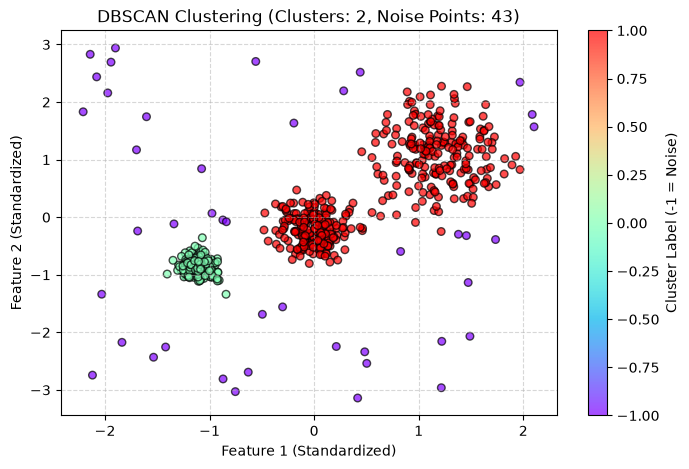

In [6]:
# Scatter plot of DBSCAN clusters
plt.figure(figsize=(8, 5))
plt.scatter(
    X_scaled[:, 0], X_scaled[:, 1],
    c=labels, cmap='rainbow', s=30, alpha=0.7, edgecolor='k'
)
plt.title(f"DBSCAN Clustering (Clusters: {n_clusters}, Noise Points: {n_noise})")
plt.xlabel("Feature 1 (Standardized)")
plt.ylabel("Feature 2 (Standardized)")
plt.colorbar(label="Cluster Label (-1 = Noise)")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()